# Skills 1 - Implementation of Machine Learning Workflow and Data Preprocessing for Student Performance Prediction

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


In [2]:
df=pd.read_csv("student_performance.csv")
df.head()

,Student_ID,Age,Gender,Study_Hours,Attendance(%),Test_Score,Grade
0,S0524,21,Female,2.7,74.0,37.0,F
1,S0603,19,Male,1.5,93.1,26.0,F
2,S0527,20,Female,6.8,97.2,88.0,A
3,S0032,18,Female,6.2,93.5,55.0,C
4,S0617,21,Male,7.4,99.2,77.0,B


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Student_ID     1020 non-null   object 
 1   Age            1020 non-null   int64  
 2   Gender         1020 non-null   object 
 3   Study_Hours    989 non-null    float64
 4   Attendance(%)  990 non-null    float64
 5   Test_Score     1020 non-null   float64
 6   Grade          1011 non-null   object 
dtypes: float64(3), int64(1), object(3)
memory usage: 55.9+ KB


In [4]:
df.describe(include='all')

,Student_ID,Age,Gender,Study_Hours,Attendance(%),Test_Score,Grade
count,1020,1020.000000,1020,989.000000,990.000000,1020.000000,1011
unique,1000,NaN,2,NaN,NaN,NaN,5
top,S0627,NaN,Male,NaN,NaN,NaN,F
freq,2,NaN,531,NaN,NaN,NaN,516
mean,NaN,20.970588,NaN,5.160768,84.871919,49.843137,NaN
std,NaN,2.008109,NaN,2.555877,10.007239,21.278630,NaN
min,NaN,18.000000,NaN,-2.000000,50.300000,0.000000,NaN
25%,NaN,19.000000,NaN,3.700000,78.000000,35.000000,NaN
50%,NaN,21.000000,NaN,5.100000,85.000000,50.000000,NaN
75%,NaN,23.000000,NaN,6.300000,91.975000,64.000000,NaN


In [5]:
df.shape

(1020, 7)

In [6]:
df.isnull().sum()

Student_ID        0
Age               0
Gender            0
Study_Hours      31
Attendance(%)    30
Test_Score        0
Grade             9
dtype: int64

In [7]:
df["Study_Hours"] = df["Study_Hours"].fillna(
    df["Study_Hours"].median()
)

df["Attendance(%)"] = df["Attendance(%)"].fillna(
    df["Attendance(%)"].median()
)

In [8]:
df = df.dropna(subset=["Grade"])

In [9]:
df.isnull().sum()  

Student_ID       0
Age              0
Gender           0
Study_Hours      0
Attendance(%)    0
Test_Score       0
Grade            0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(19)

In [11]:
df.drop_duplicates(inplace=True)

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
print(df["Gender"].unique())
print(df["Gender"].value_counts())

['Female' 'Male']
Gender
Male      515
Female    477
Name: count, dtype: int64


In [14]:
print(df["Grade"].unique())
print(df["Grade"].value_counts())

['F' 'A' 'C' 'B' 'A+']
Grade
F     507
C     257
B     148
A      48
A+     32
Name: count, dtype: int64


In [15]:
df["Age"].describe()

count    992.000000
mean      20.957661
std        2.000560
min       18.000000
25%       19.000000
50%       21.000000
75%       23.000000
max       24.000000
Name: Age, dtype: float64

In [16]:
df["Study_Hours"].describe()

count    992.000000
mean       5.198387
std        2.494340
min       -2.000000
25%        3.800000
50%        5.100000
75%        6.300000
max       25.000000
Name: Study_Hours, dtype: float64

In [17]:
df[df["Study_Hours"] < 0]

,Student_ID,Age,Gender,Study_Hours,Attendance(%),Test_Score,Grade
157,S0045,20,Male,-2.0,100.9,4.0,F
619,S0689,18,Female,-0.5,82.2,6.0,F


In [18]:
df['Study_Hours']=df['Study_Hours'].apply(lambda x: np.nan if x < 0 else x)
df[df["Study_Hours"] < 0] #to check for negative values

,Student_ID,Age,Gender,Study_Hours,Attendance(%),Test_Score,Grade


In [19]:
df["Study_Hours"] = df["Study_Hours"].fillna(
    df["Study_Hours"].median()
)

In [20]:
df.Study_Hours.isnull().sum()

np.int64(0)

In [21]:
df["Attendance(%)"].describe()

count    992.000000
mean      84.866935
std        9.785425
min       50.300000
25%       78.075000
50%       85.000000
75%       91.725000
max      115.600000
Name: Attendance(%), dtype: float64

In [22]:
invalid_attendance = df[
    (df["Attendance(%)"] < 0) |
    (df["Attendance(%)"] > 100)
]

In [23]:
invalid_attendance.head()

,Student_ID,Age,Gender,Study_Hours,Attendance(%),Test_Score,Grade
9,S0412,22,Male,5.1,104.8,49.0,F
63,S0463,20,Female,9.3,103.0,100.0,A+
88,S0714,22,Male,5.3,107.2,51.0,C
103,S0347,21,Male,4.9,106.9,55.0,C
134,S0311,24,Female,6.4,101.7,45.0,F


In [24]:
invalid_attendance['Attendance(%)'].count()

np.int64(60)

In [25]:
df.loc[
    (df["Attendance(%)"] > 100),
    "Attendance(%)"
] = 100

In [26]:
df.loc[
    (df["Attendance(%)"] < 0),
    "Attendance(%)"
]=0

In [27]:
df['Attendance(%)'].median()

85.0

In [28]:
df["Attendance(%)"] = df["Attendance(%)"].fillna(
    df["Attendance(%)"].median()
)

In [29]:
# To check
df[
    (df["Attendance(%)"] < 0) |
    (df["Attendance(%)"] > 100)
]

,Student_ID,Age,Gender,Study_Hours,Attendance(%),Test_Score,Grade


In [30]:
df["Attendance(%)"].describe()

count    992.000000
mean      84.642944
std        9.346891
min       50.300000
25%       78.075000
50%       85.000000
75%       91.725000
max      100.000000
Name: Attendance(%), dtype: float64

In [31]:
df["Test_Score"].describe()

count    992.000000
mean      50.209677
std       20.792871
min        1.000000
25%       35.000000
50%       50.000000
75%       64.000000
max      100.000000
Name: Test_Score, dtype: float64

# Training

In [32]:
X = df[
    [
        "Age",
        "Gender",
        "Study_Hours",
        "Attendance(%)",
        "Test_Score"
    ]
]

y = df["Grade"]

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [34]:
numerical_features=[
    "Age",
    "Study_Hours",
    "Attendance(%)",
    "Test_Score"
]

categorical_features=["Gender"]

In [35]:
numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [36]:
categorical_pipeline = Pipeline(
    steps=[
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

In [37]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num",numerical_pipeline,numerical_features),
        ("cat",categorical_pipeline,categorical_features)
    ]   
)

In [38]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

In [39]:
model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

In [40]:
model_pipeline.fit(
    X_train,
    y_train_encoded
)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [41]:
y_pred = model_pipeline.predict(X_test)

In [42]:
accuracy = accuracy_score(
    y_test_encoded,
    y_pred
)

print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 89.95%


In [43]:
print(
    classification_report(
        y_test_encoded,
        y_pred,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

           A       0.60      0.30      0.40        10
          A+       0.57      0.67      0.62         6
           B       0.83      0.80      0.81        30
           C       0.86      0.94      0.90        51
           F       0.98      0.98      0.98       102

    accuracy                           0.90       199
   macro avg       0.77      0.74      0.74       199
weighted avg       0.89      0.90      0.89       199



In [44]:
cm = confusion_matrix(
    y_test_encoded,
    y_pred
)

print(cm)

[[  3   2   5   0   0]
 [  2   4   0   0   0]
 [  0   0  24   6   0]
 [  0   1   0  48   2]
 [  0   0   0   2 100]]


In [48]:
y_test.value_counts()

Grade
F     102
C      51
B      30
A      10
A+      6
Name: count, dtype: int64

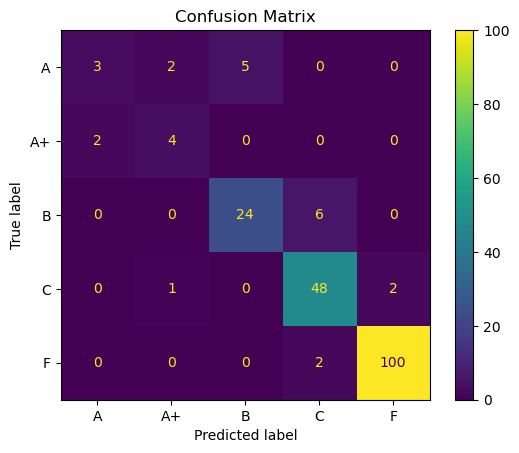

In [49]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
).plot()

plt.title("Confusion Matrix")
plt.show()

# Observations
- The preprocessing and Logistic Regression model produced an overall accuracy of 89.95%. 
- The model performed strongly for the more frequently occurring grades, especially F and C, but showed lower performance for the less frequent A and A+ categories. 
- The confusion matrix indicates that most errors occur between neighboring grade categories, particularly A–B and B–C. 
- The results also highlight the effect of class imbalance, suggesting that additional techniques such as class balancing or alternative classification models could potentially improve performance for minority grades.